In [1]:
# Import libraries
import tensorflow as tf
from tensorflow.keras import models, layers
from tensorflow.keras.callbacks import EarlyStopping
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import time
import seaborn as sns

In [2]:
# Reproducibility
SEED = 42
tf.keras.utils.set_random_seed(SEED)

# Dataset and training configuration
DATASET_DIR = Path("Dataset")
MANIFEST_PATH = DATASET_DIR / "mask_manifest.csv"

IMAGE_SIZE = (256, 256)
BATCH_SIZE = 32
EPOCHS = 100

# Initial fixed AGAL regularization strength
LAMBDA_AGAL = 0.04

print("TensorFlow version:", tf.__version__)
print("Manifest exists:", MANIFEST_PATH.exists())
print("Available devices:", tf.config.list_physical_devices())

TensorFlow version: 2.21.0
Manifest exists: True
Available devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


In [3]:

# Load the dataset manifest
df = pd.read_csv(MANIFEST_PATH)

# Check the total number of images
print("Total CT images:", len(df))

# Display available columns
print("\nAvailable columns:")
print(df.columns.tolist())

# Check the class distribution
print("\nClass distribution:")
print(df["class"].value_counts())

# Check AGAL mask eligibility
print("\nAGAL mask eligibility:")
print(df["agal_approved"].value_counts())

# Display the first five rows
display(df.head())


Total CT images: 2701

Available columns:
['image_path', 'mask_path', 'agal_mask_path', 'class', 'label', 'mask_coverage', 'component_count', 'significant_components', 'largest_component_fraction', 'border_fraction', 'border_flag', 'quality_status', 'agal_approved', 'manual_reject']

Class distribution:
class
Positive    1391
Negative    1310
Name: count, dtype: int64

AGAL mask eligibility:
agal_approved
1    2676
0      25
Name: count, dtype: int64


,image_path,mask_path,agal_mask_path,class,label,mask_coverage,component_count,significant_components,largest_component_fraction,border_fraction,border_flag,quality_status,agal_approved,manual_reject
0,Dataset/Positive/Lung MRI (1).png,Dataset/Mask_Positive/Lung MRI (1)_mask.png,Dataset/Mask_Positive/Lung MRI (1)_mask.png,Positive,1,0.207509,2,2,0.501517,0.0,0,provisionally_approved,1,0
1,Dataset/Positive/Lung MRI (10).png,Dataset/Mask_Positive/Lung MRI (10)_mask.png,Dataset/Mask_Positive/Lung MRI (10)_mask.png,Positive,1,0.208994,2,2,0.597996,0.0,0,provisionally_approved,1,0
2,Dataset/Positive/Lung MRI (100).png,Dataset/Mask_Positive/Lung MRI (100)_mask.png,Dataset/Mask_Positive/Lung MRI (100)_mask.png,Positive,1,0.247626,2,2,0.518395,0.0,0,provisionally_approved,1,0
3,Dataset/Positive/Lung MRI (1001).png,Dataset/Mask_Positive/Lung MRI (1001)_mask.png,Dataset/Mask_Positive/Lung MRI (1001)_mask.png,Positive,1,0.246483,2,2,0.512227,0.0,0,provisionally_approved,1,0
4,Dataset/Positive/Lung MRI (1002).png,Dataset/Mask_Positive/Lung MRI (1002)_mask.png,Dataset/Mask_Positive/Lung MRI (1002)_mask.png,Positive,1,0.220576,3,3,0.486528,0.0,0,provisionally_approved,1,0


In [4]:

# Check whether every CT image and corresponding mask exists

image_exists = df["image_path"].apply(
    lambda path: Path(path).is_file()
)

mask_exists = df["agal_mask_path"].apply(
    lambda path: Path(path).is_file()
)

print("Total images:", len(df))
print("Images found:", image_exists.sum())
print("Masks found:", mask_exists.sum())

print("\nMissing images:", (~image_exists).sum())
print("Missing masks:", (~mask_exists).sum())

# Stop execution if any files are missing
assert image_exists.all(), "Some CT images are missing!"
assert mask_exists.all(), "Some lung masks are missing!"

print("\nAll image-mask paths verified successfully!")


Total images: 2701
Images found: 2701
Masks found: 2701

Missing images: 0
Missing masks: 0

All image-mask paths verified successfully!


In [5]:
from sklearn.model_selection import train_test_split

# split: 80% training, 20% temporary dataset
train_df, temp_df = train_test_split(
    df,
    test_size=0.20,
    random_state=SEED,
    stratify=df["label"]
)

#split: divide temporary dataset equally into 10% validation and 10% testing
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=SEED,
    stratify=temp_df["label"]
)

# Reset indices for easier dataset handling
train_df = train_df.reset_index(drop=True)
val_df = val_df.reset_index(drop=True)
test_df = test_df.reset_index(drop=True)

# Display dataset sizes
print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

print("\nTraining class distribution:")
print(train_df["class"].value_counts())

print("\nValidation class distribution:")
print(val_df["class"].value_counts())

print("\nTesting class distribution:")
print(test_df["class"].value_counts())

# Save the splits for reproducibility
train_df.to_csv(DATASET_DIR / "train_manifest.csv", index=False)
val_df.to_csv(DATASET_DIR / "val_manifest.csv", index=False)
test_df.to_csv(DATASET_DIR / "test_manifest.csv", index=False)

print("\nDataset splits saved successfully!")


Training images: 2160
Validation images: 270
Testing images: 271

Training class distribution:
class
Positive    1112
Negative    1048
Name: count, dtype: int64

Validation class distribution:
class
Positive    139
Negative    131
Name: count, dtype: int64

Testing class distribution:
class
Positive    140
Negative    131
Name: count, dtype: int64

Dataset splits saved successfully!


In [6]:

# Load a CT image, lung mask, classification label and AGAL approval flag from the manifest.

def load_image_and_mask(image_path, mask_path, label, approved):

    # Read and preprocess the CT image
    image = tf.io.read_file(image_path)
    image = tf.image.decode_image(
        image, channels=3, expand_animations=False
    )
    image = tf.image.resize(image, IMAGE_SIZE)
    image = tf.cast(image, tf.float32) / 255.0
    image.set_shape((256, 256, 3))

    # Read and preprocess the corresponding lung mask
    mask = tf.io.read_file(mask_path)
    mask = tf.image.decode_png(mask, channels=1)

    # Nearest-neighbor resizing preserves binary mask values
    mask = tf.image.resize(
        mask, IMAGE_SIZE, method="nearest"
    )
    mask = tf.cast(mask > 127, tf.float32)
    mask.set_shape((256, 256, 1))

    # Classification target and mask eligibility
    label = tf.cast(label, tf.int32)
    approved = tf.cast(approved, tf.float32)

    return image, mask, label, approved


# Build a TensorFlow dataset from a manifest split
def create_dataset(dataframe, training=False):

    dataset = tf.data.Dataset.from_tensor_slices((
        dataframe["image_path"].astype(str).values,
        dataframe["agal_mask_path"].astype(str).values,
        dataframe["label"].astype(np.int32).values,
        dataframe["agal_approved"].astype(np.float32).values
    ))

    # Shuffle only the training dataset
    if training:
        dataset = dataset.shuffle(
            buffer_size=len(dataframe),
            seed=SEED,
            reshuffle_each_iteration=True
        )

    # Load images and masks efficiently
    dataset = dataset.map(
        load_image_and_mask,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset


# Create training, validation, and testing datasets
train_ds = create_dataset(train_df, training=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

# Inspect the first training batch
for images, masks, labels, approved in train_ds.take(1):
    print("Images:", images.shape)
    print("Masks:", masks.shape)
    print("Labels:", labels.shape)
    print("Approval flags:", approved.shape)
    print("Approved masks in batch:", int(tf.reduce_sum(approved)))


Images: (32, 256, 256, 3)
Masks: (32, 256, 256, 1)
Labels: (32,)
Approval flags: (32,)
Approved masks in batch: 32


In [7]:
# The classification architecture remains unchanged.

inputs = layers.Input(shape=(256, 256, 3))

# Convolutional Block 1
x = layers.Conv2D(32, (3, 3), activation="relu")(inputs)
x = layers.MaxPooling2D((2, 2))(x)

# Convolutional Block 2
x = layers.Conv2D(64, (3, 3), activation="relu")(x)
x = layers.MaxPooling2D((2, 2))(x)

# Convolutional Block 3
x = layers.Conv2D(64, (3, 3), activation="relu")(x)
x = layers.MaxPooling2D((2, 2))(x)

# Extract intermediate feature maps for AGAL (28 x 28 x 64)
attention_features = x

x = layers.MaxPooling2D((2, 2))(x)

# Convolutional Block 4
x = layers.Conv2D(64, (3, 3), activation="relu")(x)
x = layers.MaxPooling2D((2, 2))(x)

# Original classification head
x = layers.Flatten()(x)
x = layers.Dense(64, activation="relu")(x)
predictions = layers.Dense(2, activation="softmax")(x)

# Two outputs:
# 1. Classification predictions
# 2. Intermediate feature maps for AGAL regularization
model = models.Model(
    inputs=inputs,
    outputs=[predictions, attention_features],
    name="CNN_AGAL"
)

# Display model information
model.summary()

print("\nClassification output:", model.output_shape[0])
print("AGAL feature output:", model.output_shape[1])


Model: "CNN_AGAL"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 254, 254, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 127, 127, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 125, 125, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 62, 62, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 60, 60, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 15, 15, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 13, 13, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       147,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 240,898 (941.01 KB)

 Trainable params: 240,898 (941.01 KB)

 Non-trainable params: 0 (0.00 B)


Classification output: (None, 2)
AGAL feature output: (None, 30, 30, 64)


In [8]:

# Import AGAL functions

from attention_loss import (
    compute_attention_map,
    compute_agal_loss
)

# Testing AGAL using CNN's intermediate feature maps
for images, masks, labels, approved in train_ds.take(1):

    # Forward pass through the CNN
    predictions, feature_maps = model(images, training=False)

    # Generate attention maps using existing function
    attention_maps = compute_attention_map(
        feature_maps,
        target_size=IMAGE_SIZE
    )

    # Select only masks approved for AGAL
    approved_indices = tf.where(approved > 0.5)[:, 0]

    approved_attention = tf.gather(
        attention_maps, approved_indices
    )
    approved_masks = tf.gather(
        masks, approved_indices
    )

    # Calculate AGAL for approved masks
    agal_loss = tf.cond(
        tf.size(approved_indices) > 0,
        lambda: compute_agal_loss(
            approved_attention, approved_masks
        ),
        lambda: tf.constant(0.0, dtype=tf.float32)
    )

    print("Predictions:", predictions.shape)
    print("Feature maps:", feature_maps.shape)
    print("Attention maps:", attention_maps.shape)
    print("Approved masks:", len(approved_indices))
    print("AGAL loss:", float(agal_loss))


Predictions: (32, 2)
Feature maps: (32, 30, 30, 64)
Attention maps: (32, 256, 256, 1)
Approved masks: 32
AGAL loss: 0.8137645721435547


In [9]:
#Contextual Thompson Sampling
# Selects the AGAL regularization coefficient based on training context.

import numpy as np

class ContextualThompsonSampling:
    def __init__(self, actions, context_dim, alpha=0.5):
        """
        Initialize one Bayesian linear model for each action.

        actions: Candidate lambda values.
        context_dim: Number of context features, including bias.
        alpha: Controls exploration strength.
        """
        self.actions = np.array(actions, dtype=np.float32)
        self.context_dim = context_dim
        self.alpha = alpha

        # Independent linear model for each lambda action
        self.A = [
            np.eye(context_dim, dtype=np.float64)
            for _ in self.actions
        ]
        self.b = [
            np.zeros(context_dim, dtype=np.float64)
            for _ in self.actions
        ]

        self.rng = np.random.default_rng(SEED)

    def select_action(self, context):
        """
        Sample a reward estimate for each lambda and
        select the action with the highest sampled reward.
        """
        context = np.asarray(context, dtype=np.float64)

        sampled_rewards = []

        for A, b in zip(self.A, self.b):
            A_inv = np.linalg.inv(A)
            mean = A_inv @ b
            covariance = (self.alpha ** 2) * A_inv

            sampled_theta = self.rng.multivariate_normal(
                mean, covariance
            )

            sampled_rewards.append(sampled_theta @ context)

        action_index = int(np.argmax(sampled_rewards))

        return action_index, float(self.actions[action_index])

    def update(self, action_index, context, reward):
        """
        Update the selected action's linear model
        using the observed validation reward.
        """
        context = np.asarray(context, dtype=np.float64)

        self.A[action_index] += np.outer(context, context)
        self.b[action_index] += reward * context


# Candidate regularization strengths
LAMBDA_ACTIONS = [0.0, 0.01, 0.05, 0.1]

# Context: bias + classification loss + AGAL loss + mask coverage
CONTEXT_DIM = 4

bandit = ContextualThompsonSampling(
    actions=LAMBDA_ACTIONS,
    context_dim=CONTEXT_DIM,
    alpha=0.5
)

print("Contextual Thompson Sampling initialized!")
print("Lambda actions:", bandit.actions)
print("Context dimension:", bandit.context_dim)


Contextual Thompson Sampling initialized!
Lambda actions: [0.   0.01 0.05 0.1 ]
Context dimension: 4


In [10]:

# CNN training and validation steps
# Lambda will be selected dynamically by the contextual bandit.

optimizer = tf.keras.optimizers.Adam(learning_rate=0.0001)

classification_loss_fn = (
    tf.keras.losses.SparseCategoricalCrossentropy()
)

@tf.function
def train_step(images, masks, labels, approved, lambda_value):

    with tf.GradientTape() as tape:

        # Forward pass through our existing CNN
        predictions, feature_maps = model(
            images, training=True
        )

        # Classification loss
        ce_loss = classification_loss_fn(
            labels, predictions
        )

        # Attention maps from our existing module
        attention_maps = compute_attention_map(
            feature_maps,
            target_size=IMAGE_SIZE
        )

        # Use only masks approved for AGAL
        approved_indices = tf.where(approved > 0.5)[:, 0]

        approved_attention = tf.gather(
            attention_maps, approved_indices
        )

        approved_masks = tf.gather(
            masks, approved_indices
        )

        # Anatomically Guided Attention Loss
        agal_loss = tf.cond(
            tf.size(approved_indices) > 0,
            lambda: compute_agal_loss(
                approved_attention,
                approved_masks
            ),
            lambda: tf.constant(0.0, dtype=tf.float32)
        )

        # Dynamic lambda selected by contextual bandit
        total_loss = (
            ce_loss
            + tf.cast(lambda_value, tf.float32) * agal_loss
        )

    # Backpropagation
    gradients = tape.gradient(
        total_loss, model.trainable_variables
    )

    optimizer.apply_gradients(
        zip(gradients, model.trainable_variables)
    )

    accuracy = tf.reduce_mean(
        tf.cast(
            tf.equal(
                tf.argmax(predictions, axis=1, output_type=tf.int32),
                labels
            ),
            tf.float32
        )
    )

    return total_loss, ce_loss, agal_loss, accuracy


@tf.function
def validation_step(images, masks, labels, approved):

    # No weight updates during validation
    predictions, feature_maps = model(
        images, training=False
    )

    ce_loss = classification_loss_fn(
        labels, predictions
    )

    attention_maps = compute_attention_map(
        feature_maps,
        target_size=IMAGE_SIZE
    )

    approved_indices = tf.where(approved > 0.5)[:, 0]

    agal_loss = tf.cond(
        tf.size(approved_indices) > 0,
        lambda: compute_agal_loss(
            tf.gather(attention_maps, approved_indices),
            tf.gather(masks, approved_indices)
        ),
        lambda: tf.constant(0.0, dtype=tf.float32)
    )

    accuracy = tf.reduce_mean(
        tf.cast(
            tf.equal(
                tf.argmax(predictions, axis=1, output_type=tf.int32),
                labels
            ),
            tf.float32
        )
    )

    return ce_loss, agal_loss, accuracy


print("Training and validation functions created successfully!")
print("Optimizer: Adam")
print("Learning rate:", 0.001)
print("Lambda: Dynamically selected by contextual Thompson Sampling")


Training and validation functions created successfully!
Optimizer: Adam
Learning rate: 0.001
Lambda: Dynamically selected by contextual Thompson Sampling


In [11]:
# Context extraction and reward function

REWARD_BETA = 0.5


def create_context(ce_loss, agal_loss, mask_coverage):
    """
    Create the context vector observed by the bandit
    before it selects lambda.
    """

    context = np.array([
        1.0,                  # Bias
        float(ce_loss),       # Classification loss
        float(agal_loss),     # Outside-lung attention ratio
        float(mask_coverage)  # Fraction of image inside lung mask
    ], dtype=np.float64)

    return context


def calculate_reward(
    previous_accuracy,
    current_accuracy,
    previous_agal,
    current_agal
):
    """
    Reward classification improvement and
    reduction in outside-lung attention.
    """

    accuracy_improvement = (
        current_accuracy - previous_accuracy
    )

    attention_improvement = (
        previous_agal - current_agal
    )

    reward = (
        accuracy_improvement
        + REWARD_BETA * attention_improvement
    )

    return float(reward)


# Test the functions with illustrative values
example_context = create_context(
    ce_loss=0.65,
    agal_loss=0.84,
    mask_coverage=0.20
)

example_reward = calculate_reward(
    previous_accuracy=0.80,
    current_accuracy=0.83,
    previous_agal=0.84,
    current_agal=0.78
)

print("Context vector:", example_context)
print("Context shape:", example_context.shape)
print("Example reward:", round(example_reward, 4))


Context vector: [1.   0.65 0.84 0.2 ]
Context shape: (4,)
Example reward: 0.06


In [12]:
# CONTEXTUAL BANDIT-GUIDED CNN TRAINING LOOP
# 1. Checkpoint configuration
CHECKPOINT_DIR = Path("checkpoints")
CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

BEST_WEIGHTS_PATH = (
    CHECKPOINT_DIR / "best_bandit_cnn.weights.h5"
)


# 2. Evaluate classification and anatomical attention
def evaluate_dataset(dataset):
    """
    Evaluate the CNN without updating weights.

    Returns:
        - Classification loss (CE)
        - AGAL loss (approved masks only)
        - Classification accuracy
    """

    total_ce = 0.0
    total_agal = 0.0
    total_correct = 0.0

    total_samples = 0
    total_approved = 0

    for images, masks, labels, approved in dataset:

        ce, agal, accuracy = validation_step(
            images,
            masks,
            labels,
            approved
        )

        batch_size = int(tf.shape(labels)[0])

        approved_count = int(
            tf.reduce_sum(
                tf.cast(approved > 0.5, tf.int32)
            )
        )

        # Classification metrics include all samples
        total_ce += float(ce) * batch_size
        total_correct += float(accuracy) * batch_size

        # AGAL includes only approved masks
        total_agal += float(agal) * approved_count

        total_samples += batch_size
        total_approved += approved_count

    return {
        "ce_loss": total_ce / total_samples,
        "agal_loss": total_agal / max(total_approved, 1),
        "accuracy": total_correct / total_samples
    }



# 3. Calculate lung mask coverage

def get_mask_coverage(dataframe):
    """
    Calculate average lung-mask coverage using
    approved masks from the training manifest.
    """

    approved_rows = dataframe[
        dataframe["agal_approved"] == 1
    ]

    return float(
        approved_rows["mask_coverage"].mean()
    )



# 4. Contextual Bandit-Guided Training

def train_with_contextual_bandit(
    epochs=100,
    patience=15
):
    """
    Train CNN using contextual Thompson Sampling.

    At every epoch:
      1. Observe current CNN context
      2. Select lambda using Thompson Sampling
      3. Train CNN with CE + lambda * AGAL
      4. Evaluate validation performance
      5. Calculate reward and update bandit
      6. Save best model and apply early stopping
    """

    history = []

    best_val_accuracy = -1.0
    best_val_ce = float("inf")

    wait = 0

    # Dataset-level mask coverage context
    mask_coverage = get_mask_coverage(train_df)

    # Evaluate CNN before training begins
    previous_val = evaluate_dataset(val_ds)

    print("Initial validation:", previous_val)
    print("=" * 90)

   
    # Epoch loop
    

    for epoch in range(epochs):

        start_time = time.time()

        
        # STEP 1: Observe current training context
        

        current_train = evaluate_dataset(train_ds)

        context = create_context(
            ce_loss=current_train["ce_loss"],
            agal_loss=current_train["agal_loss"],
            mask_coverage=mask_coverage
        )

        
        # STEP 2: Thompson Sampling selects lambda
        

        action_index, selected_lambda = (
            bandit.select_action(context)
        )

        
        # STEP 3: Train CNN for one epoch
       

        train_ce_sum = 0.0
        train_agal_sum = 0.0
        train_correct_sum = 0.0

        train_samples = 0
        train_approved = 0

        for images, masks, labels, approved in train_ds:

            total, ce, agal, accuracy = train_step(
                images,
                masks,
                labels,
                approved,
                tf.constant(
                    selected_lambda,
                    dtype=tf.float32
                )
            )

            batch_size = int(tf.shape(labels)[0])

            approved_count = int(
                tf.reduce_sum(
                    tf.cast(approved > 0.5, tf.int32)
                )
            )

            # Classification metrics
            train_ce_sum += float(ce) * batch_size

            train_correct_sum += (
                float(accuracy) * batch_size
            )

            # AGAL metrics use approved masks only
            train_agal_sum += (
                float(agal) * approved_count
            )

            train_samples += batch_size
            train_approved += approved_count

        
        # STEP 4: Calculate epoch training metrics
       

        epoch_train_accuracy = (
            train_correct_sum / train_samples
        )

        epoch_train_ce = (
            train_ce_sum / train_samples
        )

        epoch_train_agal = (
            train_agal_sum / max(train_approved, 1)
        )

        # Combined epoch-level loss
        epoch_train_total = (
            epoch_train_ce
            + selected_lambda * epoch_train_agal
        )

        
        # STEP 5: Evaluate validation performance
        

        current_val = evaluate_dataset(val_ds)

        epoch_val_accuracy = current_val["accuracy"]
        epoch_val_ce = current_val["ce_loss"]
        epoch_val_agal = current_val["agal_loss"]

        # Validation total loss using selected lambda
        epoch_val_total = (
            epoch_val_ce
            + selected_lambda * epoch_val_agal
        )

        
        # STEP 6: Calculate contextual bandit reward
        

        reward = calculate_reward(
            previous_accuracy=previous_val["accuracy"],
            current_accuracy=epoch_val_accuracy,
            previous_agal=previous_val["agal_loss"],
            current_agal=epoch_val_agal
        )

        # Update Thompson Sampling using observed reward
        bandit.update(
            action_index=action_index,
            context=context,
            reward=reward
        )

        
        # STEP 7: Save all metrics in training history
        

        epoch_record = {
            "epoch": epoch + 1,
            "lambda": selected_lambda,

            "train_accuracy": epoch_train_accuracy,
            "val_accuracy": epoch_val_accuracy,

            "train_ce": epoch_train_ce,
            "val_ce": epoch_val_ce,

            "train_agal": epoch_train_agal,
            "val_agal": epoch_val_agal,

            "train_total": epoch_train_total,
            "val_total": epoch_val_total,

            "reward": reward
        }

        history.append(epoch_record)

        
        # STEP 8: Save best model
        

        # Prioritize validation accuracy.
        # Use lower validation CE as a tie-breaker.

        improved = (
            epoch_val_accuracy > best_val_accuracy
            or (
                epoch_val_accuracy == best_val_accuracy
                and epoch_val_ce < best_val_ce
            )
        )

        if improved:

            best_val_accuracy = epoch_val_accuracy
            best_val_ce = epoch_val_ce

            model.save_weights(
                str(BEST_WEIGHTS_PATH)
            )

            wait = 0

        else:
            wait += 1

        
        # STEP 9: Display all training metrics
        

        elapsed = time.time() - start_time

        print(
            f"\nEpoch {epoch + 1:03d}/{epochs} | "
            f"Lambda={selected_lambda:.3f} | "
            f"Time={elapsed:.1f}s"
        )

        print(
            f"  TRAIN | "
            f"Accuracy={epoch_train_accuracy:.4f} | "
            f"CE={epoch_train_ce:.4f} | "
            f"AGAL={epoch_train_agal:.4f} | "
            f"Total Loss={epoch_train_total:.4f}"
        )

        print(
            f"  VAL   | "
            f"Accuracy={epoch_val_accuracy:.4f} | "
            f"CE={epoch_val_ce:.4f} | "
            f"AGAL={epoch_val_agal:.4f} | "
            f"Total Loss={epoch_val_total:.4f}"
        )

        print(
            f"  BANDIT | "
            f"Reward={reward:+.4f} | "
            f"Early Stopping={wait}/{patience}"
        )

        if improved:
            print("  Best model checkpoint saved!")

        print("-" * 90)

        
        # STEP 10: Update previous validation state
        

        previous_val = current_val

        
        # STEP 11: Early stopping
       

        if wait >= patience:

            print(
                f"\nEarly stopping triggered "
                f"at epoch {epoch + 1}"
            )

            print(
                f"Best validation accuracy: "
                f"{best_val_accuracy:.4f}"
            )

            break

    
    # Return and save complete training history
    

    history_df = pd.DataFrame(history)

    history_df.to_csv(
        CHECKPOINT_DIR / "bandit_training_history.csv",
        index=False
    )

    print("\nTraining completed!")
    print("Total epochs trained:", len(history_df))
    print("Best validation accuracy:", best_val_accuracy)
    print("Best checkpoint:", BEST_WEIGHTS_PATH)

    return history_df


print("Contextual bandit training loop configured!")
print("Early stopping patience: 15 epochs")
print("Checkpoint:", BEST_WEIGHTS_PATH)
print("Metrics: Accuracy, CE, AGAL, Total Loss, Lambda, Reward")


Contextual bandit training loop configured!
Early stopping patience: 15 epochs
Checkpoint: checkpoints/best_bandit_cnn.weights.h5
Metrics: Accuracy, CE, AGAL, Total Loss, Lambda, Reward


In [13]:
history_df = train_with_contextual_bandit(
    epochs=50,
    patience=15
)

# Save the complete training history
history_df.to_csv(
    "checkpoints/bandit_training_history.csv",
    index=False
)

print("\nTraining completed!")
print("Total epochs trained:", len(history_df))

# Identify the best epoch using the same checkpoint criterion:
# highest validation accuracy, then lowest validation CE loss.
best_epoch = history_df.sort_values(
    by=["val_accuracy", "val_ce"],
    ascending=[False, True]
).iloc[0]

print("\nBest epoch:", int(best_epoch["epoch"]))
print("Best validation accuracy:", best_epoch["val_accuracy"])
print("Validation AGAL at best epoch:", best_epoch["val_agal"])
print("Lambda selected at best epoch:", best_epoch["lambda"])

print("\nTraining history saved.")
print("Best model checkpoint:", BEST_WEIGHTS_PATH)

Initial validation: {'ce_loss': 0.6920313751256024, 'agal_loss': 0.8086026319751033, 'accuracy': 0.5592592588177434}

Epoch 001/50 | Lambda=0.100 | Time=35.5s
  TRAIN | Accuracy=0.6977 | CE=0.6234 | AGAL=0.8131 | Total Loss=0.7048
  VAL   | Accuracy=0.8667 | CE=0.4333 | AGAL=0.8248 | Total Loss=0.5157
  BANDIT | Reward=+0.2993 | Early Stopping=0/15
  Best model checkpoint saved!
------------------------------------------------------------------------------------------

Epoch 002/50 | Lambda=0.000 | Time=37.3s
  TRAIN | Accuracy=0.8329 | CE=0.4005 | AGAL=0.8345 | Total Loss=0.4005
  VAL   | Accuracy=0.8889 | CE=0.2922 | AGAL=0.8346 | Total Loss=0.2922
  BANDIT | Reward=+0.0173 | Early Stopping=0/15
  Best model checkpoint saved!
------------------------------------------------------------------------------------------

Epoch 003/50 | Lambda=0.050 | Time=38.0s
  TRAIN | Accuracy=0.8731 | CE=0.3074 | AGAL=0.8392 | Total Loss=0.3494
  VAL   | Accuracy=0.8852 | CE=0.2689 | AGAL=0.8366 | Tot

In [14]:

#  Evaluate best contextual-bandit CNN on test data

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score
)

# Load the best saved CNN weights
model.load_weights(str(BEST_WEIGHTS_PATH))

# Collect predictions and evaluation losses
y_true = []
y_pred = []
y_prob = []

test_ce_sum = 0.0
test_agal_sum = 0.0
total_samples = 0
total_approved = 0

for images, masks, labels, approved in test_ds:

    predictions, feature_maps = model(
        images, training=False
    )

    # Classification loss
    ce = classification_loss_fn(labels, predictions)

    # Attention map from our existing module
    attention_maps = compute_attention_map(
        feature_maps,
        target_size=IMAGE_SIZE
    )

    # AGAL only on approved masks
    approved_indices = tf.where(approved > 0.5)[:, 0]
    approved_count = int(tf.size(approved_indices))

    if approved_count > 0:
        agal = compute_agal_loss(
            tf.gather(attention_maps, approved_indices),
            tf.gather(masks, approved_indices)
        )
        test_agal_sum += float(agal) * approved_count

    batch_size = int(tf.shape(labels)[0])

    test_ce_sum += float(ce) * batch_size
    total_samples += batch_size
    total_approved += approved_count

    y_true.extend(labels.numpy().tolist())
    y_pred.extend(
        tf.argmax(predictions, axis=1).numpy().tolist()
    )
    y_prob.extend(predictions.numpy().tolist())

# Dataset-level metrics
test_ce = test_ce_sum / total_samples
test_agal = test_agal_sum / max(total_approved, 1)
test_accuracy = accuracy_score(y_true, y_pred)

# Reference combined loss, NOT the historical training loss
REFERENCE_LAMBDA = 0.05
reference_total_loss = (
    test_ce + REFERENCE_LAMBDA * test_agal
)

print("TEST DATASET RESULTS")
print("-" * 45)
print(f"Test samples: {total_samples}")
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Classification loss: {test_ce:.4f}")
print(f"AGAL loss: {test_agal:.4f}")
print(f"Reference total loss (λ=0.05): {reference_total_loss:.4f}")

print("\nClassification report:")
print(
    classification_report(
        y_true,
        y_pred,
        target_names=["Negative", "Positive"],
        zero_division=0
    )
)

print("\nConfusion matrix:")
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
print(cm)


TEST DATASET RESULTS
---------------------------------------------
Test samples: 271
Test accuracy: 0.9299
Classification loss: 0.2430
AGAL loss: 0.8235
Reference total loss (λ=0.05): 0.2842

Classification report:
              precision    recall  f1-score   support

    Negative       0.88      0.99      0.93       131
    Positive       0.99      0.87      0.93       140

    accuracy                           0.93       271
   macro avg       0.94      0.93      0.93       271
weighted avg       0.94      0.93      0.93       271


Confusion matrix:
[[130   1]
 [ 18 122]]


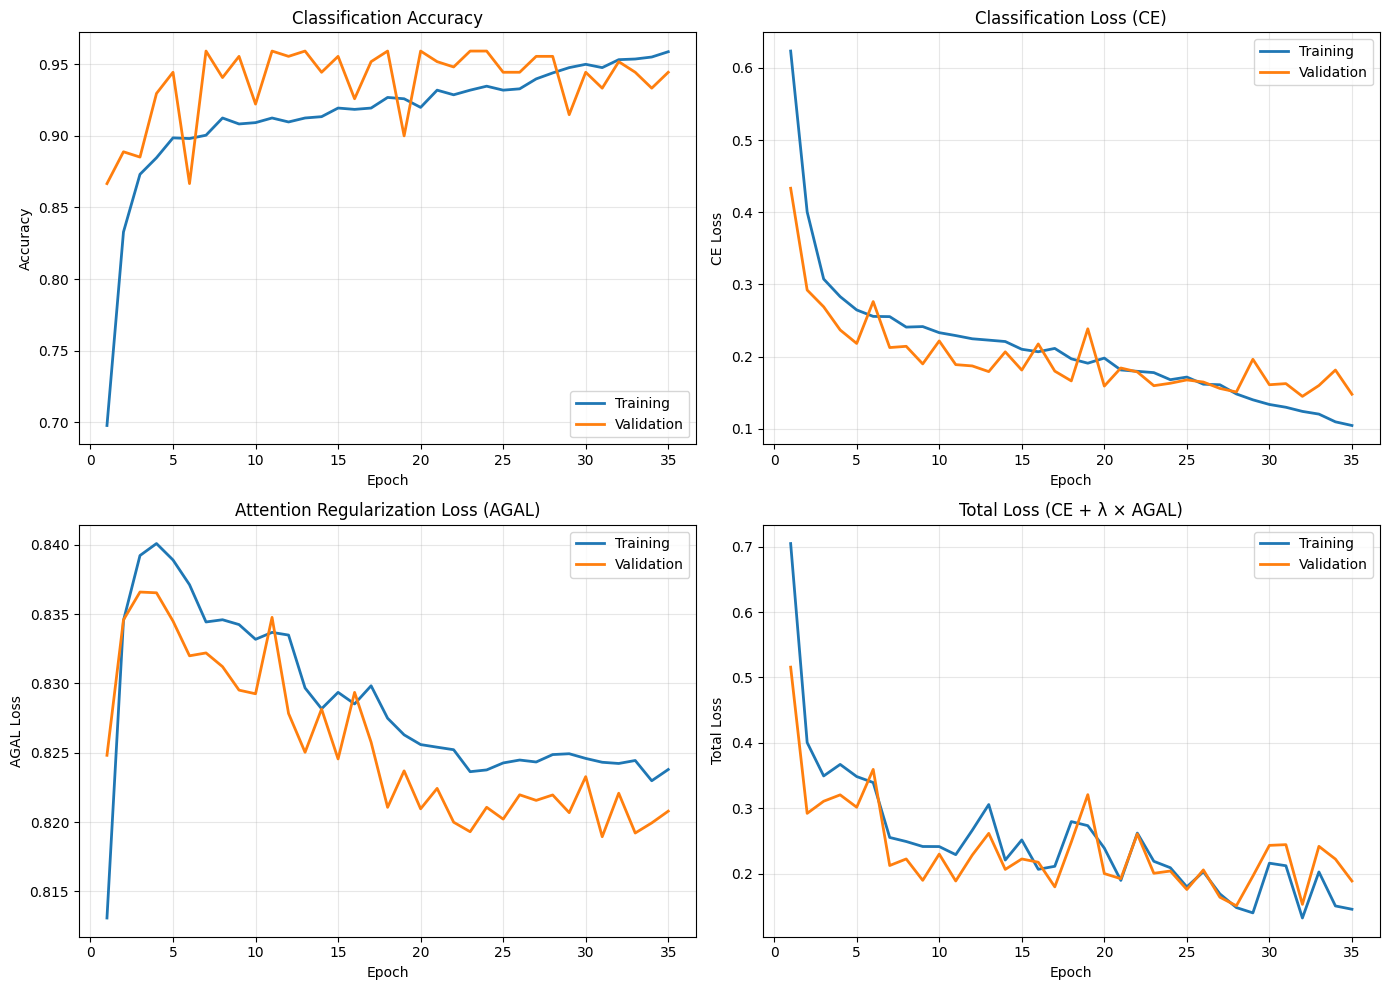

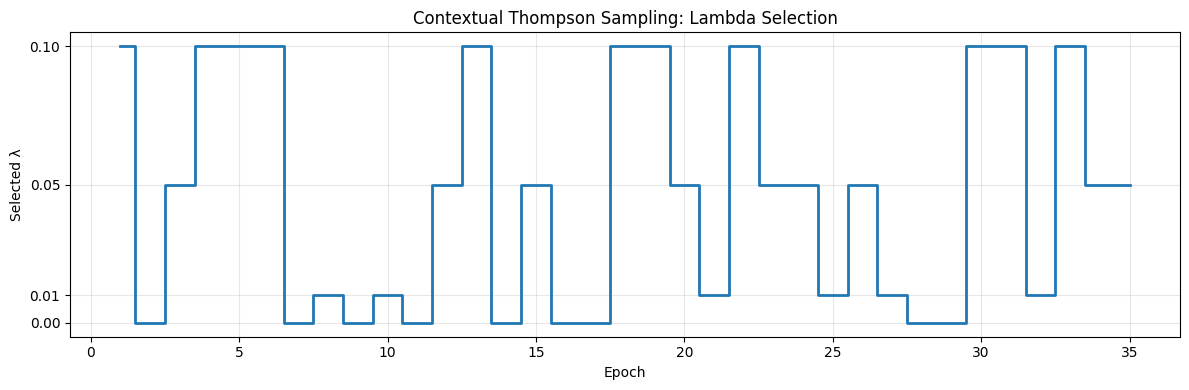

In [15]:
# Load saved training history
history_df = pd.read_csv(
    "checkpoints/bandit_training_history.csv"
)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

epochs = history_df["epoch"]

# 1. Accuracy
axes[0, 0].plot(
    epochs, history_df["train_accuracy"],
    label="Training", linewidth=2
)
axes[0, 0].plot(
    epochs, history_df["val_accuracy"],
    label="Validation", linewidth=2
)
axes[0, 0].set_title("Classification Accuracy")
axes[0, 0].set_ylabel("Accuracy")
axes[0, 0].legend()

# 2. Cross-entropy loss
axes[0, 1].plot(
    epochs, history_df["train_ce"],
    label="Training", linewidth=2
)
axes[0, 1].plot(
    epochs, history_df["val_ce"],
    label="Validation", linewidth=2
)
axes[0, 1].set_title("Classification Loss (CE)")
axes[0, 1].set_ylabel("CE Loss")
axes[0, 1].legend()

# 3. AGAL loss
axes[1, 0].plot(
    epochs, history_df["train_agal"],
    label="Training", linewidth=2
)
axes[1, 0].plot(
    epochs, history_df["val_agal"],
    label="Validation", linewidth=2
)
axes[1, 0].set_title("Attention Regularization Loss (AGAL)")
axes[1, 0].set_ylabel("AGAL Loss")
axes[1, 0].legend()

# 4. Total loss
axes[1, 1].plot(
    epochs, history_df["train_total"],
    label="Training", linewidth=2
)
axes[1, 1].plot(
    epochs, history_df["val_total"],
    label="Validation", linewidth=2
)
axes[1, 1].set_title("Total Loss (CE + λ × AGAL)")
axes[1, 1].set_ylabel("Total Loss")
axes[1, 1].legend()

for ax in axes.flat:
    ax.set_xlabel("Epoch")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(
    "checkpoints/training_metrics.png",
    dpi=300, bbox_inches="tight"
)
plt.show()

# Separate figure: Lambda selection
plt.figure(figsize=(12, 4))
plt.step(
    epochs, history_df["lambda"],
    where="mid", linewidth=2
)
plt.yticks(sorted(history_df["lambda"].unique()))
plt.xlabel("Epoch")
plt.ylabel("Selected λ")
plt.title("Contextual Thompson Sampling: Lambda Selection")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(
    "checkpoints/lambda_selection.png",
    dpi=300, bbox_inches="tight"
)
plt.show()


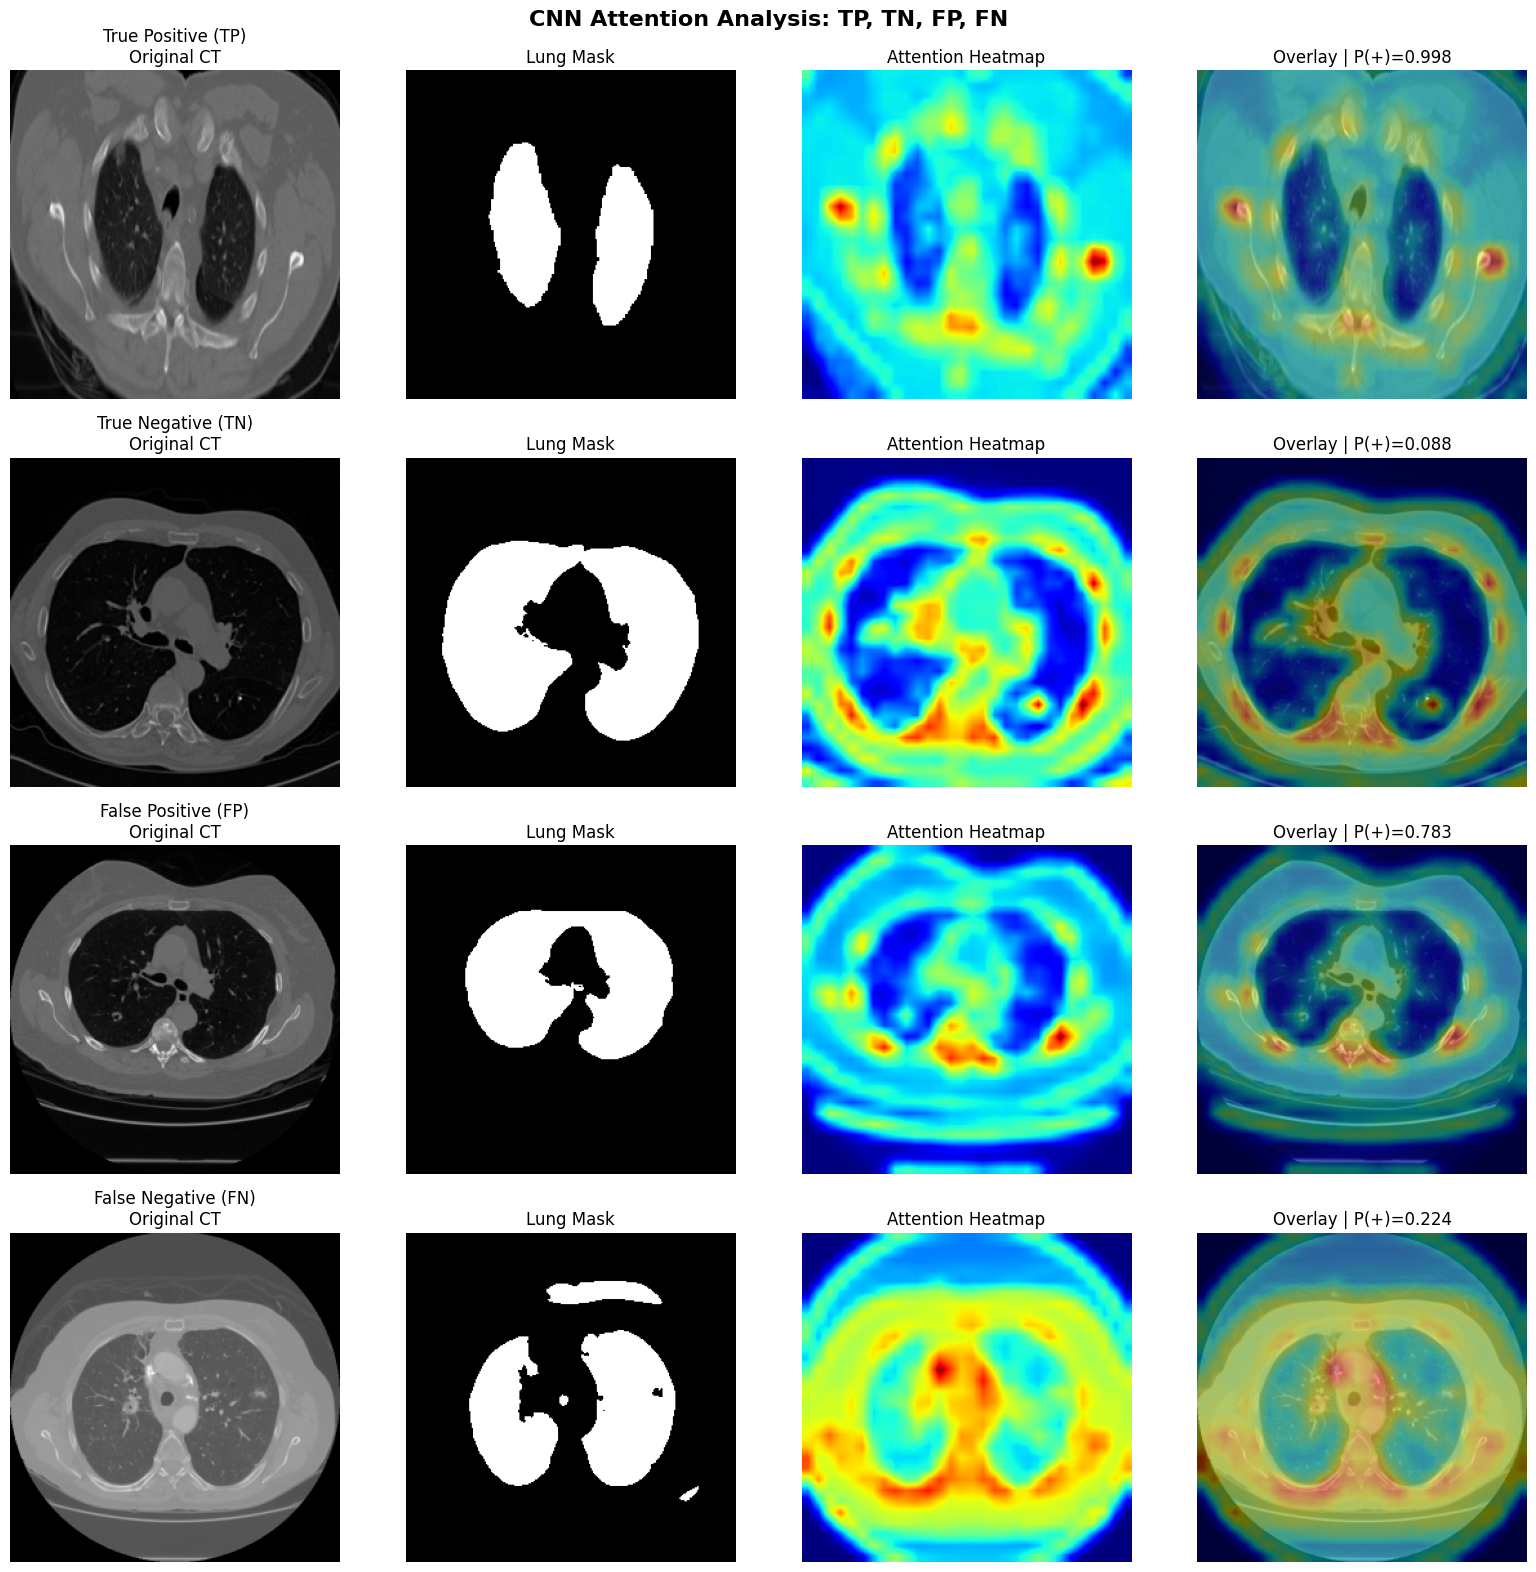

In [16]:
# Ensure best checkpoint is loaded
model.load_weights(str(BEST_WEIGHTS_PATH))

# Collect test images, masks, labels and predictions
test_images = []
test_masks = []
true_labels = []
pred_labels = []
positive_probs = []

for images, masks, labels, approved in test_ds:
    predictions, _ = model(images, training=False)

    test_images.extend(images.numpy())
    test_masks.extend(masks.numpy())
    true_labels.extend(labels.numpy())
    pred_labels.extend(
        tf.argmax(predictions, axis=1).numpy()
    )
    positive_probs.extend(predictions[:, 1].numpy())

true_labels = np.array(true_labels)
pred_labels = np.array(pred_labels)

categories = {
    "True Positive (TP)": (1, 1),
    "True Negative (TN)": (0, 0),
    "False Positive (FP)": (0, 1),
    "False Negative (FN)": (1, 0)
}

fig, axes = plt.subplots(4, 4, figsize=(16, 16))

for row, (category, (true_class, pred_class)) in enumerate(
    categories.items()
):
    matching = np.where(
        (true_labels == true_class) &
        (pred_labels == pred_class)
    )[0]

    if len(matching) == 0:
        for ax in axes[row]:
            ax.axis("off")
        axes[row, 0].text(
            0.5, 0.5, f"No {category}",
            ha="center", va="center"
        )
        continue

    # Select first example in each category
    idx = matching[0]

    image = test_images[idx]
    mask = np.squeeze(test_masks[idx])

    image_batch = tf.expand_dims(image, axis=0)

    predictions, feature_maps = model(
        image_batch, training=False
    )

    attention_map = compute_attention_map(
        feature_maps,
        target_size=IMAGE_SIZE
    )[0, :, :, 0].numpy()

    # Original CT
    axes[row, 0].imshow(image)
    axes[row, 0].set_title(f"{category}\nOriginal CT")

    # Lung mask
    axes[row, 1].imshow(mask, cmap="gray")
    axes[row, 1].set_title("Lung Mask")

    # Attention heatmap
    axes[row, 2].imshow(
        attention_map,
        cmap="jet", vmin=0, vmax=1
    )
    axes[row, 2].set_title("Attention Heatmap")

    # Overlay
    axes[row, 3].imshow(image)
    axes[row, 3].imshow(
        attention_map,
        cmap="jet",
        alpha=0.45,
        vmin=0,
        vmax=1
    )
    axes[row, 3].set_title(
        f"Overlay | P(+)={positive_probs[idx]:.3f}"
    )

    for ax in axes[row]:
        ax.axis("off")

plt.suptitle(
    "CNN Attention Analysis: TP, TN, FP, FN",
    fontsize=16, fontweight="bold"
)
plt.tight_layout()
plt.savefig(
    "checkpoints/attention_outcomes.png",
    dpi=300, bbox_inches="tight"
)
plt.savefig("heatmap.png")
plt.show()


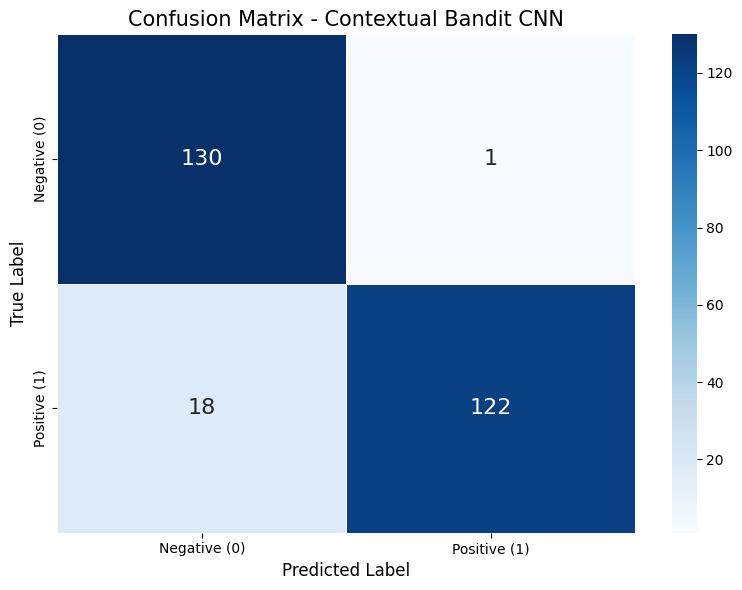

True Positives (TP): 122
True Negatives (TN): 130
False Positives (FP): 1
False Negatives (FN): 18


In [17]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Calculate confusion matrix from actual test predictions
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

# Plot confusion matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negative (0)", "Positive (1)"],
    yticklabels=["Negative (0)", "Positive (1)"],
    linewidths=0.5,
    linecolor="white",
    cbar=True,
    annot_kws={"size": 16}
)

plt.title(
    "Confusion Matrix - Contextual Bandit CNN",
    fontsize=15
)

plt.xlabel("Predicted Label", fontsize=12)
plt.ylabel("True Label", fontsize=12)

plt.tight_layout()

# Save publication-quality figure
plt.savefig(
    "checkpoints/confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# Display individual prediction outcomes
tn, fp, fn, tp = cm.ravel()

print(f"True Positives (TP): {tp}")
print(f"True Negatives (TN): {tn}")
print(f"False Positives (FP): {fp}")
print(f"False Negatives (FN): {fn}")
